# Quasi Montecarlo
## Simulación de Procesos Financieros 

Ximena Muñoz 

28/10/26


## Introducción

En este notebook vamos a estudiar los métodos Monte Carlo y Quasi-Monte Carlo, los cuales utilizan muestras para resolver problemas matemáticos y financieros.

Primero aprenderemos cómo se generan números aleatorios y cómo se distribuyen. Después utilizaremos esos números para aproximar integrales y calcular probabilidades.

Finalmente, aplicaremos estos métodos a problemas financieros, específicamente para calcular el precio de opciones europeas y asiáticas.

El objetivo es entender cómo funcionan estos métodos, cómo se aplican y cómo cambian los resultados dependiendo de la cantidad y el tipo de muestras que utilizamos.




# 1. Muestreo uniforme

## ¿Qué es el muestreo uniforme?

El muestreo uniforme consiste en generar valores aleatorios dentro de un intervalo, donde todos los valores tienen la misma probabilidad de aparecer.

En este ejercicio utilizaremos una distribución uniforme entre 0 y 1, que se representa de la siguiente manera:

$$
X \sim U(0,1)
$$

Esto significa que los valores generados estarán entre 0 y 1.

Por ejemplo, podemos obtener números como 0.15, 0.38, 0.62 o 0.91. Todos pertenecen al intervalo establecido.

## ¿Qué queremos hacer?

Vamos a generar 50 números aleatorios entre 0 y 1 y posteriormente utilizaremos un histograma para observar cómo se distribuyen.

El objetivo es identificar cómo se comportan las muestras y entender qué significa que una distribución sea uniforme. 


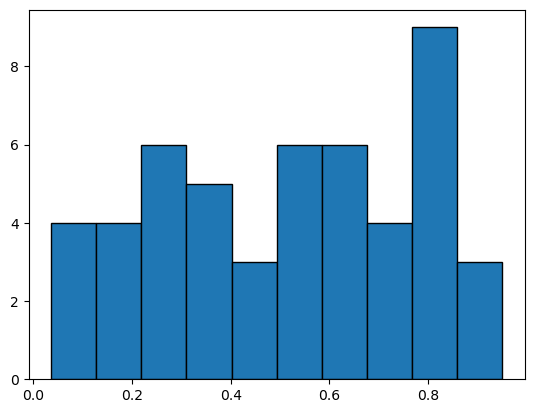

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(20)
muestras = np.random.uniform(0,1, 50)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()



## Interpretación del histograma de 50 muestras

En el histograma podemos observar cómo se distribuyen los 50 números aleatorios que generamos.

El eje horizontal representa los valores entre 0 y 1, mientras que el eje vertical representa la frecuencia, es decir, cuántas veces aparecen valores dentro de cada intervalo.

Podemos observar que las barras tienen diferentes alturas. Esto ocurre porque los números se generan aleatoriamente y no necesariamente vamos a obtener la misma cantidad de valores en cada intervalo.

Aunque estamos trabajando con una distribución uniforme, esto no significa que todas las barras deban tener exactamente la misma altura, especialmente cuando utilizamos pocas muestras.



## Efecto del tamaño de muestra

Ahora que conocemos cómo se generan las muestras, vamos a repetir el procedimiento utilizando diferentes cantidades de observaciones.

Trabajaremos con 100, 500, 1,000 y 1,000,000 de muestras.

## ¿Por qué aumentamos la cantidad de muestras?

Cuando utilizamos pocas observaciones, las frecuencias de los intervalos pueden variar bastante.

Al aumentar el número de muestras, esperamos que las frecuencias relativas de los intervalos sean cada vez más parecidas.

Esto nos permite observar cómo se comporta una distribución uniforme cuando tenemos una mayor cantidad de datos.


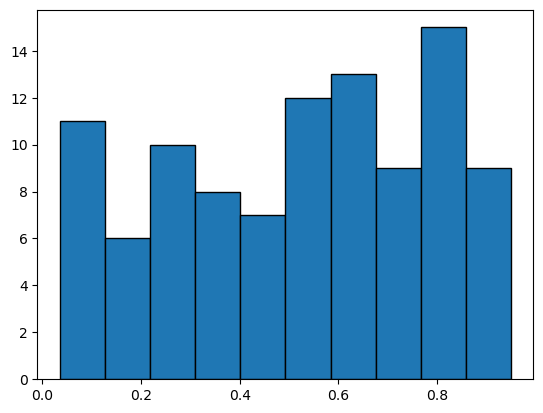

In [2]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 100)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

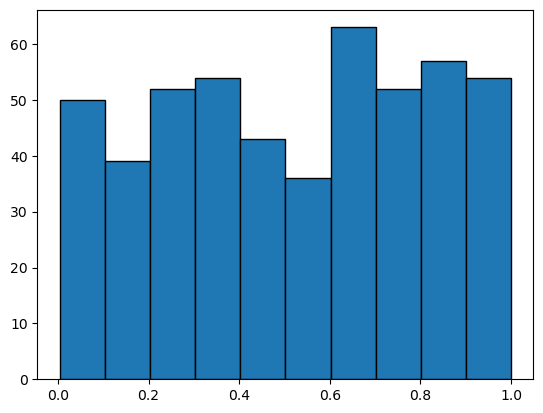

In [3]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 500)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

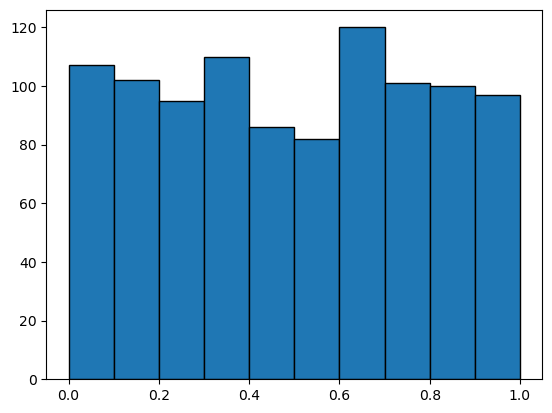

In [4]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 1000)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()

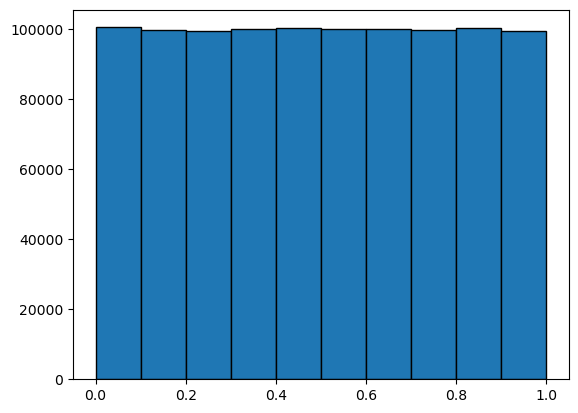

In [5]:
np.random.seed(20)
muestras = np.random.uniform(0,1, 1000000)

plt.hist(muestras, bins=10, edgecolor='black')
plt.show()


## Interpretación de los histogramas

Al comparar los histogramas podemos observar que, conforme aumenta el número de muestras, la distribución presenta un comportamiento más uniforme.

Con 100 o 500 observaciones todavía podemos encontrar diferencias importantes entre las alturas de las barras.

Sin embargo, cuando utilizamos una cantidad mucho mayor de muestras, las frecuencias relativas de los intervalos tienden a acercarse entre sí.

Esto ocurre porque tenemos más observaciones y podemos representar mejor el comportamiento de la distribución uniforme.

Es importante recordar que las frecuencias no tienen que ser exactamente iguales, ya que seguimos trabajando con muestras aleatorias.



# 2. Integración por Monte Carlo

## ¿Qué es una integral?

Una integral nos permite calcular el área que se encuentra debajo de una curva entre dos límites.

En este ejercicio queremos calcular la siguiente integral:

$$
\int_0^1 x^2\,dx
$$

Esto significa que queremos encontrar el área debajo de la función:

$$
f(x)=x^2
$$

desde 0 hasta 1.

## ¿Cuál es el valor exacto?

Antes de utilizar simulaciones, podemos resolver la integral directamente mediante las reglas de integración:

$$
\int_0^1 x^2\,dx
=
\left[\frac{x^3}{3}\right]_0^1
$$

Sustituyendo los límites:

$$
=\frac{1^3}{3}-\frac{0^3}{3}
$$

Por lo tanto:

$$
I=\frac{1}{3}\approx 0.333333
$$

Este será nuestro valor de referencia para comparar los resultados de las simulaciones.

## ¿Cómo funciona la integración por Monte Carlo?

El método Monte Carlo utiliza números aleatorios para aproximar el valor de una integral.

En lugar de calcular directamente el área, generamos diferentes valores dentro del intervalo, evaluamos la función en cada uno y calculamos el promedio de los resultados.

La fórmula general es:

$$
\hat I_m=(b-a)\frac{1}{m}
\sum_{i=1}^{m}f(x_i)
$$

Donde:

- $a$ representa el límite inferior.
- $b$ representa el límite superior.
- $m$ representa la cantidad de muestras.
- $x_i$ representa cada muestra generada.
- $f(x_i)$ representa el resultado de evaluar la función en cada muestra.

En nuestro ejercicio tenemos:

$$
f(x)=x^2,\quad a=0,\quad b=1
$$

Por lo tanto, la fórmula se simplifica a:

$$
\hat I_m=\frac{1}{m}\sum_{i=1}^{m}x_i^2
$$

## ¿Cómo calculamos el error?

Después de obtener una aproximación, necesitamos compararla con el valor exacto de la integral.

Para esto utilizamos el error absoluto:

$$
Error=|I-\hat I_m|
$$

En nuestro ejercicio:

$$
Error=\left|\frac{1}{3}-\hat I_m\right|
$$

Mientras menor sea el error, más cercana será nuestra aproximación al resultado exacto.


In [6]:
np.random.seed(20)
import pandas as pd
def f(x):
    return x**2

m=[]
fu=[]
e=[]
res = pd.DataFrame()
for i in [100, 500, 1000, 5000]:
    x = np.random.uniform(0,1, i)
    y = f(x)
    m.append(i)
    fu.append(y.mean() * (1-0))
    e.append(abs(y.mean() * (1-0) - 1/3))

res['m'] = m
res['f(c) (b-a)'] = fu
res['Error'] = e

res
    

,m,f(c) (b-a),Error
0,100,0.337295,0.003962
1,500,0.349306,0.015973
2,1000,0.322216,0.011118
3,5000,0.342234,0.008900



## Interpretación de los resultados de Monte Carlo

La tabla muestra las aproximaciones de la integral utilizando diferentes cantidades de muestras: 100, 500, 1,000 y 5,000.

La columna de aproximación representa el resultado que obtuvimos mediante el promedio de los valores de la función.

La columna de error muestra la diferencia absoluta entre nuestra aproximación y el valor exacto de la integral, que es aproximadamente 0.333333.

Podemos observar que los resultados no siempre se acercan al valor exacto de manera constante. Esto es normal porque Monte Carlo utiliza números aleatorios.

Al aumentar el número de muestras, generalmente esperamos que las estimaciones sean más estables y que el error disminuya en promedio.



# 3. Quasi-Monte Carlo con Sobol

## ¿Qué es Quasi-Monte Carlo?

Quasi-Monte Carlo es un método que utiliza secuencias cuasialeatorias para aproximar integrales.

La diferencia principal con Monte Carlo tradicional es la forma en que se generan las muestras.

- Monte Carlo utiliza números pseudoaleatorios.
- Quasi-Monte Carlo utiliza secuencias cuasialeatorias que buscan distribuir los puntos de una manera más uniforme.

En este ejercicio utilizaremos el método de Sobol, que permite generar estas secuencias.

## ¿Qué es una secuencia de Sobol?

Una secuencia de Sobol es un conjunto de puntos diseñado para cubrir un intervalo o espacio de manera uniforme.

Esto ayuda a evitar que los puntos se concentren demasiado en algunas zonas y dejen otras con pocas observaciones.

## ¿Qué queremos hacer?

Vamos a repetir la misma integral del ejercicio anterior:

$$
\int_0^1 x^2\,dx=\frac{1}{3}
$$

La diferencia es que ahora utilizaremos muestras generadas mediante Sobol en lugar de números pseudoaleatorios tradicionales.

Después calcularemos el error QMC y lo agregaremos a nuestra tabla para comparar ambos métodos.


In [7]:
from scipy.stats import qmc, norm
error_sobol = []

for i in [100, 500, 1000, 5000]:
    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sobol.random(i).flatten()
    y = f(u)
    rest = y.mean()
    error_sobol.append(abs(rest - 1/3))

res['Error qmc'] = error_sobol
res


/opt/anaconda3/lib/python3.13/site-packages/scipy/stats/_qmc.py:993: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sample = self._random(n, workers=workers)


,m,f(c) (b-a),Error,Error qmc
0,100,0.337295,0.003962,0.001264
1,500,0.349306,0.015973,0.000174
2,1000,0.322216,0.011118,0.000223
3,5000,0.342234,0.008900,0.000043



## Interpretación de los resultados de Quasi-Monte Carlo

En esta parte obtuvimos una nueva aproximación de la integral utilizando las muestras generadas mediante Sobol.

La tabla conserva las aproximaciones y los errores de Monte Carlo, y agrega una nueva columna llamada Error qmc.

Esta columna representa la diferencia absoluta entre el resultado obtenido con Sobol y el valor exacto de la integral.

Al comparar ambos errores podemos observar qué método obtuvo una aproximación más cercana a 1/3.

En general, las secuencias de Sobol buscan cubrir el intervalo de una manera más uniforme, lo que puede ayudar a obtener aproximaciones más precisas.

Sin embargo, los resultados también dependen de la cantidad de muestras y de la secuencia utilizada.



# 4. Estimación de una probabilidad

## ¿Qué es una distribución normal?

Una distribución normal es una distribución de probabilidad que tiene una forma parecida a una campana.

La mayoría de los valores se encuentran alrededor de la media, mientras que los valores más alejados de ella suelen aparecer con menor frecuencia.

En este ejercicio trabajaremos con una variable aleatoria que sigue una distribución normal:

$$
X\sim N(50,10)
$$

Esto significa que utilizaremos una distribución con:

- Media de 50.
- Desviación estándar de 10.

## ¿Qué queremos calcular?

Queremos estimar la probabilidad de que la variable aleatoria tome un valor mayor que 60:

$$
P(X>60)
$$

En otras palabras, queremos conocer qué proporción de los valores generados es mayor que 60.

## ¿Cómo lo vamos a calcular?

Utilizaremos dos métodos:

1. Monte Carlo tradicional.
2. Quasi-Monte Carlo mediante Sobol.

Para Monte Carlo generaremos números aleatorios que sigan una distribución normal.

Para Quasi-Monte Carlo primero generaremos puntos Sobol entre 0 y 1 y después los transformaremos a una distribución normal mediante la función inversa de la distribución acumulada.

Finalmente, compararemos las probabilidades obtenidas con ambos métodos.


In [12]:
np.random.seed(20)

probability_mc = []
probability_qmc = []

for i in m:
    samples_mc = np.random.normal(50, 10, i)

    sobol = qmc.Sobol(d=1, scramble=True, seed=20)
    u = sobol.random(i).flatten()
    samples_sobol = norm.ppf(u, loc=50, scale=10)

    prob_mc = np.mean(samples_mc > 60)
    prob_qmc = np.mean(samples_sobol > 60)

    probability_mc.append(prob_mc)
    probability_qmc.append(prob_qmc)

results_problem = pd.DataFrame({
    'm': m,
    'MC': probability_mc,
    'QMC': probability_qmc
})

results_problem


/opt/anaconda3/lib/python3.13/site-packages/scipy/stats/_qmc.py:993: UserWarning: The balance properties of Sobol' points require n to be a power of 2.
  sample = self._random(n, workers=workers)


,m,MC,QMC
0,100,0.1700,0.1600
1,500,0.1800,0.1600
2,1000,0.1550,0.1600
3,5000,0.1592,0.1588



## Interpretación de los resultados

La tabla presenta las probabilidades estimadas mediante Monte Carlo y Quasi-Monte Carlo para diferentes cantidades de muestras.

La columna MC corresponde a la proporción de valores mayores que 60 obtenida mediante números aleatorios tradicionales.

La columna QMC representa la proporción obtenida mediante las muestras Sobol transformadas a una distribución normal.

Podemos observar que los dos métodos buscan estimar la misma probabilidad, pero pueden producir resultados diferentes debido a la forma en que generan las muestras.

Al aumentar el número de observaciones, esperamos que las estimaciones se acerquen a la probabilidad teórica.



# 5. Valuación de opciones financieras mediante Monte Carlo y Quasi-Monte Carlo

## ¿Qué es una opción financiera?

Una opción financiera es un contrato que le otorga a su comprador el derecho, pero no la obligación, de comprar o vender un activo a un precio establecido.

En este ejercicio trabajaremos con opciones Call.

Una opción Call le da al comprador el derecho de comprar un activo a un precio determinado, conocido como precio de ejercicio o Strike.

## ¿Qué diferencia existe entre una Call europea y una Call asiática?

**Call europea:**

Su pago depende del precio del activo al final del periodo, es decir, en la fecha de vencimiento.

Su fórmula de pago es:

$$
\max(S_T-K,0)
$$

**Call asiática:**

Su pago depende del promedio de los precios del activo durante el periodo de simulación.

En nuestro ejercicio utilizaremos el promedio de los precios de cada trayectoria.

Su fórmula de pago es:

$$
\max(\bar S-K,0)
$$

Donde:

- $S_T$ representa el precio del activo al vencimiento.
- $\bar S$ representa el promedio de los precios durante el periodo.
- $K$ representa el precio de ejercicio de la opción.

## ¿Qué queremos hacer?

Vamos a simular diferentes trayectorias del precio de una acción y utilizaremos esas trayectorias para calcular el precio estimado de una Call europea y una Call asiática.

Realizaremos el procedimiento mediante dos métodos:

1. Monte Carlo tradicional.
2. Quasi-Monte Carlo utilizando Sobol.

Al final compararemos los precios obtenidos para observar las diferencias entre ambos métodos.



## 5.1. Parámetros del ejercicio

Antes de realizar las simulaciones, necesitamos establecer los datos que utilizaremos para representar el comportamiento del precio de la acción.

Los parámetros son:

| Variable | Significado | Valor |
|---|---|---:|
| $S_0$ | Precio inicial de la acción | 100 |
| $r$ | Tasa de interés libre de riesgo | 0.05 |
| $\sigma$ | Volatilidad | 0.20 |
| $T$ | Tiempo hasta el vencimiento | 1 año |
| $n$ | Número de periodos | 252 |
| $K$ | Precio de ejercicio | 100 |
| $M$ | Número de trayectorias | 1,024 |

También calculamos la duración de cada periodo:

$$
dt=\frac{T}{n}
$$

En este caso, dividimos un año entre 252 periodos para representar aproximadamente los días de operación de un año en el mercado financiero.

Estos parámetros serán utilizados tanto en Monte Carlo como en Quasi-Monte Carlo, para que podamos comparar los resultados bajo las mismas condiciones.



## 5.2. Simulación de precios mediante Monte Carlo

Primero utilizaremos el método Monte Carlo tradicional para generar las trayectorias del precio de la acción.

Para esto necesitamos generar números aleatorios que sigan una distribución normal estándar:

$$
Z\sim N(0,1)
$$

Estos valores representan los cambios aleatorios que pueden afectar el precio de la acción durante cada periodo.

Para calcular la evolución del precio utilizamos la siguiente fórmula:

$$
S_t=S_{t-1}
e^{(r-\frac{\sigma^2}{2})dt+\sigma\sqrt{dt}Z_t}
$$

Donde:

- $S_t$ es el precio de la acción en el periodo actual.
- $S_{t-1}$ es el precio del periodo anterior.
- $r$ es la tasa de interés.
- $\sigma$ es la volatilidad.
- $dt$ es la duración de cada periodo.
- $Z_t$ es el valor aleatorio generado para ese periodo.

De esta manera, cada trayectoria representa una posible evolución del precio de la acción durante un año.


## 5.3. Cálculo de la Call europea mediante Monte Carlo

Una vez que tenemos las trayectorias simuladas, podemos calcular el precio de una Call europea.

Recordemos que esta opción depende del precio de la acción al final del periodo.

Primero obtenemos el último precio de cada trayectoria y lo comparamos con el precio de ejercicio.

El pago de la opción se calcula mediante:

$$
\max(S_T-K,0)
$$

Si el precio final de la acción es mayor que el precio de ejercicio, la opción tiene un pago positivo. Si es menor, el pago es cero.

Después calculamos el promedio de los pagos y lo descontamos al valor presente utilizando:

$$
C=e^{-rT}E[\max(S_T-K,0)]
$$

Así obtenemos una estimación del precio de la Call europea mediante Monte Carlo.



## 5.4. Cálculo de la Call asiática mediante Monte Carlo

Ahora calcularemos el precio de una Call asiática utilizando las mismas trayectorias generadas anteriormente.

La diferencia es que esta opción no depende únicamente del precio final de la acción, sino del promedio de los precios durante todo el periodo.

Primero calculamos el promedio de los precios de cada trayectoria:

$$
\bar S=\frac{1}{n}\sum_{t=1}^{n}S_t
$$

Después calculamos el pago de la opción:

$$
\max(\bar S-K,0)
$$

Finalmente, obtenemos el promedio de los pagos y lo descontamos al valor presente.

De esta manera podemos estimar el precio de una Call asiática mediante Monte Carlo.


## 5.6. Cálculo de las opciones mediante Quasi-Monte Carlo

Una vez que tenemos las trayectorias generadas mediante Sobol, podemos calcular nuevamente el precio de las dos opciones.

Primero calculamos la Call europea utilizando el último precio de cada trayectoria.

Después calculamos la Call asiática utilizando el promedio de los precios de cada trayectoria.

Los procedimientos son los mismos que utilizamos anteriormente con Monte Carlo. La diferencia es que ahora trabajamos con trayectorias generadas mediante secuencias cuasialeatorias.

Esto nos permite comparar los precios estimados por ambos métodos.


In [9]:
import numpy as np
from scipy.stats import qmc, norm

# Datos
S0 = 100
r = 0.05
sigma = 0.20
T = 1
n = 252
K = 100
M = 1024

dt = T / n

# Monte Carlo
np.random.seed(20)
Z_mc = np.random.normal(0, 1, (M, n))

S_mc = S0 * np.exp(np.cumsum(
    (r - sigma**2 / 2) * dt
    + sigma * np.sqrt(dt) * Z_mc,
    axis=1
))

# Call europea MC
call_europea_mc = np.exp(-r*T) * np.mean(
    np.maximum(S_mc[:, -1] - K, 0)
)

# Call asiática MC
promedio_mc = np.mean(S_mc, axis=1)
call_asian_mc = np.exp(-r*T) * np.mean(
    np.maximum(promedio_mc - K, 0)
)

# Quasi-Monte Carlo (Sobol)
sobol = qmc.Sobol(d=n, scramble=True, seed=42)
u = sobol.random_base2(m=10)
Z_qmc = norm.ppf(u)

S_qmc = S0 * np.exp(np.cumsum(
    (r - sigma**2 / 2) * dt
    + sigma * np.sqrt(dt) * Z_qmc,
    axis=1
))

# Call europea QMC
call_europea_qmc = np.exp(-r*T) * np.mean(
    np.maximum(S_qmc[:, -1] - K, 0)
)

# Call asiática QMC
promedio_qmc = np.mean(S_qmc, axis=1)
call_asian_qmc = np.exp(-r*T) * np.mean(
    np.maximum(promedio_qmc - K, 0)
)

# Resultados
print("CALL EUROPEA")
print("Monte Carlo:", call_europea_mc)
print("Quasi-Monte Carlo:", call_europea_qmc)

print("\nCALL ASIATICA")
print("Monte Carlo:", call_asian_mc)
print("Quasi-Monte Carlo:", call_asian_qmc)



CALL EUROPEA
Monte Carlo: 11.638811094019326
Quasi-Monte Carlo: 10.412575834637336

CALL ASIATICA
Monte Carlo: 6.410507018550081
Quasi-Monte Carlo: 5.699478709127668



## 5.7. Interpretación de los resultados

En este ejercicio obtuvimos cuatro resultados:

- Call europea mediante Monte Carlo.
- Call europea mediante Quasi-Monte Carlo.
- Call asiática mediante Monte Carlo.
- Call asiática mediante Quasi-Monte Carlo.

Podemos observar que los precios obtenidos no son exactamente iguales, ya que los métodos utilizan diferentes formas de generar las muestras.

También podemos observar que la Call europea y la Call asiática tienen diferentes precios porque sus pagos dependen de información distinta.

La Call europea utiliza el precio final de la acción, mientras que la Call asiática utiliza el promedio de los precios durante el periodo.

Estos resultados nos permiten comparar cómo cambia la valuación de las opciones dependiendo del método de simulación utilizado.




# 6. Comparación con Black-Scholes

## ¿Qué es el modelo Black-Scholes?

Black-Scholes es un modelo matemático utilizado para calcular el precio teórico de una opción financiera europea.

A diferencia de Monte Carlo y Quasi-Monte Carlo, que utilizan simulaciones para aproximar el precio, Black-Scholes utiliza una fórmula matemática.

En esta sección calcularemos el precio teórico de una Call europea y lo compararemos con los resultados que obtuvimos anteriormente mediante los métodos de simulación.

## ¿Cómo funciona?

Primero calculamos dos valores llamados $d_1$ y $d_2$:

$$
d_1=
\frac{\ln(S_0/K)+(r+\sigma^2/2)T}
{\sigma\sqrt{T}}
$$

$$
d_2=d_1-\sigma\sqrt{T}
$$

Después utilizamos estos valores para calcular el precio de la opción:

$$
C=S_0N(d_1)-Ke^{-rT}N(d_2)
$$

Donde:

- $S_0$ es el precio inicial de la acción.
- $K$ es el precio de ejercicio.
- $r$ es la tasa de interés libre de riesgo.
- $\sigma$ es la volatilidad.
- $T$ es el tiempo hasta el vencimiento.
- $N(d_1)$ y $N(d_2)$ representan valores de la distribución normal acumulada.

El resultado de esta fórmula será nuestro precio teórico de referencia para la Call europea.



In [10]:
import numpy as np
from scipy.stats import norm, qmc

# Datos del problema
S0 = 100
r = 0.05
sigma = 0.20
T = 1
n = 252
K = 100
M = 1024


## Cálculo del precio mediante Black-Scholes

Primero utilizamos los mismos parámetros que establecimos para las simulaciones anteriores.

Después calculamos $d_1$ y $d_2$ mediante sus respectivas fórmulas.

Finalmente, sustituimos los resultados en la fórmula de Black-Scholes para obtener el precio teórico de la Call europea.

Este valor nos permite tener una referencia para evaluar qué tan cercanas fueron las estimaciones que obtuvimos mediante Monte Carlo y Quasi-Monte Carlo.


In [11]:
d1 = (np.log(S0 / K) + (r + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

call_europea = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

print("Call Europea - Black-Scholes:", round(call_europea, 6))



Call Europea - Black-Scholes: 10.450584



## Interpretación de los resultados

El modelo Black-Scholes nos proporciona un precio teórico de referencia para la Call europea.

En nuestro ejercicio, el resultado obtenido mediante este modelo es aproximadamente:

$$
C=10.450584
$$

Ahora podemos compararlo con los precios estimados anteriormente mediante Monte Carlo y Quasi-Monte Carlo.

Si los precios de las simulaciones se encuentran cerca del resultado de Black-Scholes, significa que nuestras estimaciones están aproximando el precio teórico de la opción.

Es importante recordar que Black-Scholes se utiliza como referencia para la Call europea. No estamos utilizando esta fórmula para calcular directamente el precio de la Call asiática.




# 7. Conclusión general

A lo largo de este notebook aprendimos cómo funcionan los métodos Monte Carlo y Quasi-Monte Carlo y cómo podemos utilizarlos para resolver diferentes problemas matemáticos y financieros.

Primero trabajamos con muestras de una distribución uniforme y observamos cómo cambia su comportamiento cuando aumentamos la cantidad de observaciones.

Después utilizamos estas muestras para aproximar una integral mediante Monte Carlo y Quasi-Monte Carlo, comparando los errores obtenidos con ambos métodos.

También estimamos una probabilidad utilizando una distribución normal y observamos las diferencias entre los resultados de las dos técnicas.

Finalmente, aplicamos las simulaciones a la valuación de opciones financieras, calculando el precio de una Call europea y una Call asiática. Para la opción europea también utilizamos el modelo Black-Scholes como referencia teórica.

En general, estos ejercicios nos permitieron comprender que las simulaciones son herramientas útiles para aproximar resultados y resolver problemas en los que necesitamos trabajar con diferentes escenarios posibles.
